In [2]:
import requests
import pandas as pd
import json
import os

In [3]:
def get_metric(url):
    """
    Member 2 - Step 2: Downloads time-series data from UKHSA API.
    Handles pagination metadata and extracts records into a DataFrame.
    """
    params = {"page_size": 365}
    headers = {"Accept": "application/json"}
    
    r = requests.get(url, params=params, headers=headers)
    if r.status_code == 200:
        data = r.json()
        # Handles both paginated 'results' and direct 'body' structures
        records = data.get("results", data.get("body", data))
        return pd.DataFrame(records)
    else:
        print(f"Error {r.status_code}: {r.text[:200]}")
        return pd.DataFrame()

print("get_metric defined successfully!")

get_metric defined successfully!


In [4]:
ecoli_url = (
    "https://api.ukhsa-dashboard.data.gov.uk/themes/infectious_disease/sub_themes/antimicrobial_resistance/"
    "topics/E-coli/geography_types/UKHSA%20Region/geographies/London/metrics/e-coli_testing_bacteraemiaPercentResistantRollingMonth"
)

ecoli_raw = get_metric(ecoli_url)

if not ecoli_raw.empty:
    ecoli_df = pd.DataFrame()
    ecoli_df["date"] = pd.to_datetime(ecoli_raw["date"])
    ecoli_df["region"] = ecoli_raw.get("geography", "London")
    ecoli_df["resistance"] = ecoli_raw["metric_value"].astype(float)
    ecoli_df["bacteria"] = "E_coli"
    
    # Use the stratum column if available, else label standard antibiotic class
    if "stratum" in ecoli_raw.columns:
        ecoli_df["resistance_type"] = ecoli_raw["stratum"]
    else:
        ecoli_df["resistance_type"] = "ThirdGenCephalosporin"
    
    ecoli_df = ecoli_df.sort_values("date")
    print(f"Successfully loaded and standardised {len(ecoli_df)} records for E. coli:")
    display(ecoli_df.head(10))
else:
    print("DataFrame returned empty. Check response.")

Successfully loaded and standardised 365 records for E. coli:


,date,region,resistance,bacteria,resistance_type
0,2020-04-01,London,0.58,E_coli,Carbapenems
1,2020-04-01,London,15.55,E_coli,Gentamicin
2,2020-04-01,London,24.45,E_coli,Third Generation Cephalosporins
3,2020-04-01,London,13.42,E_coli,Piperacillin with tazobactam
4,2020-04-01,London,47.07,E_coli,Co-amoxiclav
5,2020-04-01,London,1.22,E_coli,Amikacin
6,2020-04-01,London,31.31,E_coli,Ciprofloxacin
13,2020-05-01,London,15.46,E_coli,Gentamicin
12,2020-05-01,London,29.35,E_coli,Ciprofloxacin
10,2020-05-01,London,1.28,E_coli,Amikacin


In [5]:
import os
os.makedirs("../data/processed", exist_ok=True)
ecoli_df.to_csv("../data/processed/amr_all_bacteria.csv", index=False)
print("Saved clean file to data/processed/amr_all_bacteria.csv")

Saved clean file to data/processed/amr_all_bacteria.csv


In [8]:
print("Unique resistance types:", ecoli_df["resistance_type"].unique())
print("Date range:", ecoli_df["date"].min(), "to", ecoli_df["date"].max())
print("Total records:", len(ecoli_df))

Unique resistance types: ['Carbapenems' 'Gentamicin' 'Third Generation Cephalosporins'
 'Piperacillin with tazobactam' 'Co-amoxiclav' 'Amikacin' 'Ciprofloxacin']
Date range: 2020-04-01 00:00:00 to 2024-08-01 00:00:00
Total records: 365


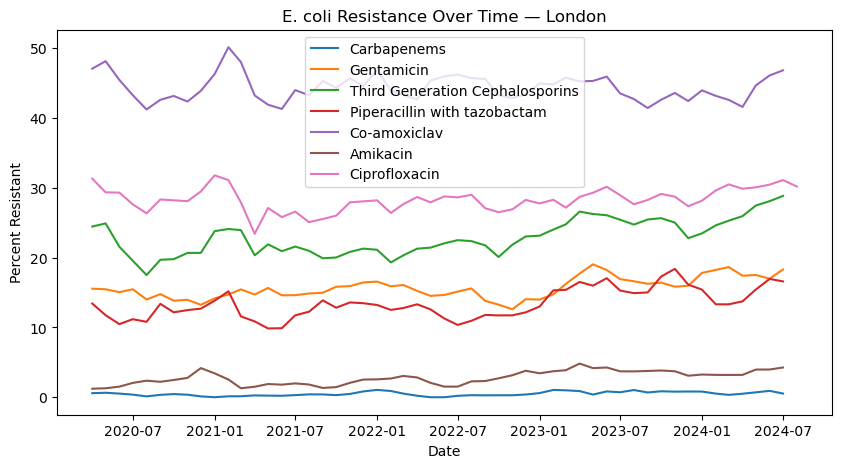

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
for rtype in ecoli_df["resistance_type"].unique():
    subset = ecoli_df[ecoli_df["resistance_type"] == rtype]
    plt.plot(subset["date"], subset["resistance"], label=rtype)

plt.legend()
plt.title("E. coli Resistance Over Time — London")
plt.ylabel("Percent Resistant")
plt.xlabel("Date")
plt.show()